# Breast Cancer Wisconsin: which tumour measurements separate malignant from benign?

**The question:** 569 patients had a small sample of a breast lump examined under a microscope. A computer measured the cell nuclei in the image (how big, how rough, how irregular), giving 30 numbers per patient. Doctors then confirmed whether each tumour was **malignant** (cancer) or **benign**. Which measurements tell the two apart, which ones are just copies of each other, and how good, and how *safe*, can a screening model be?

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. H1: which measurements differ?
6. H2: measurements that are copies of each other
7. A short, readable model and its odds ratios
8. H3: a leak-free model ladder
9. H4: the safety trade-off (missing cancer vs false alarms)
10. Takeaways
11. Limitations

> **This notebook replaces three older ones** (an "original" 699-sample logistic-regression notebook, a 24 MB EDA notebook and a modelling notebook). They now live together in one story, built on the 569-patient *Diagnostic* dataset that ships inside scikit-learn, so there is nothing to download.

**Run it:** `uv run jupyter lab ML/breast-cancer-wisconsin/01_breast_cancer.ipynb`, or *Run All* in any Jupyter.

## 1. 💡 The simple analogy

Think of a **smoke alarm**.

- If it *never* rings, it's useless, and a **missed fire** is a disaster.
- If it rings every time you make toast, you'll stop trusting it, but a **false alarm** is only an annoyance.

A cancer screening model is a smoke alarm for tumours. The two kinds of mistake are *not* equally bad: **missing a cancer (false negative) is far worse than flagging a benign lump for a second look (false positive)**. So accuracy alone ("how often is it right?") is the wrong scoreboard. We will keep asking two questions instead:

- **Sensitivity:** of the tumours that really are malignant, what share did the alarm catch?
- **Specificity:** of the tumours that really are benign, what share did the alarm correctly leave alone?

In this notebook "positive" always means **malignant**, because that is what we are trying to catch.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed keeps the notebook reproducible and avoids "magic numbers". With the seed fixed, every bootstrap and cross-validation split comes out the same each time you run it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import make_scorer, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

OUT_DIR = Path("outputs")
SEED = 42
N_BOOTSTRAP = 1_000
CV_SPLITS, CV_REPEATS = 5, 10
TARGET_SENSITIVITY = 0.99
FAMILY_COLORS = {"mean": "#2a9d8f", "error": "#b8bcc2", "worst": "#264653"}
TEAL, ORANGE, NAVY, GREY = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)

## 3. Audit the data first

*What:* load the data and check what each column means. *Why:* before testing anything we need to know how many patients we have, how lopsided the classes are, and what the 30 columns really are.

**The 30 features** are 10 measurements of the cell nuclei, each summarised three ways per patient (a nucleus image contains many cells):

| Measurement | Plain-English meaning |
|---|---|
| radius, perimeter, area | how big the nuclei are |
| texture | how uneven the grey shades are |
| smoothness, compactness, concavity, concave points, symmetry, fractal dimension | how smooth, dented or irregular the outline is |

and the three summaries are the **mean** (typical nucleus), the **error** (standard error, how much the nuclei vary) and the **worst** (the mean of the three largest values, i.e. the most extreme cells).

> **A coding trap.** scikit-learn stores the target as `0 = malignant, 1 = benign`, which is the *opposite* of what most people expect. We flip it so that **1 = malignant** (the thing we want to catch), so sensitivity and "positive" mean what they should.

In [2]:
def load_data() -> tuple[pd.DataFrame, pd.Series]:
    """Loads the Wisconsin Diagnostic data with malignant as the positive class.

    Returns:
        Feature table (569 x 30) and a target where 1 = malignant, 0 = benign.

    Raises:
        ValueError: If the data does not have the expected shape or has nulls.
    """
    bunch = load_breast_cancer(as_frame=True)
    features, target = bunch.data, (bunch.target == 0).astype(int).rename("malignant")
    if features.shape != (569, 30) or features.isna().any().any():
        raise ValueError(f"Unexpected data: shape={features.shape}")
    return features, target


X, y = load_data()
FAMILY = pd.Series(
    ["error" if "error" in c else "worst" if "worst" in c else "mean" for c in X.columns],
    index=X.columns,
)
print(f"Patients: {len(X)}   Features: {X.shape[1]}   Missing values: {int(X.isna().sum().sum())}")
print(f"Malignant: {y.sum()} ({y.mean():.1%})   Benign: {(1 - y).sum()} ({1 - y.mean():.1%})")
print(f"Exact duplicate rows: {X.duplicated().sum()}")
X.iloc[:, :10].describe().round(2).T

Patients: 569   Features: 30   Missing values: 0
Malignant: 212 (37.3%)   Benign: 357 (62.7%)
Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


**How to read this.** There are **569 patients** and no missing values or duplicates. **37.3% are malignant** (212 patients) and 62.7% benign (357). That imbalance matters: a "model" that says *everyone is benign* would be right 62.7% of the time while catching **zero** cancers, which is why accuracy alone is misleading, and why we will always split the data in a way that keeps the same malignant share in every fold (**stratified** cross-validation).

The table shows the 10 "mean" measurements. Notice that they live on **very different scales**: mean area is around 650 while mean smoothness is around 0.1. Models that measure distances or penalise coefficients (kNN, logistic regression, SVM) need those scaled to be comparable, and we'll do that **inside** each model pipeline later so it can't leak.

## 4. 🔬 Hypotheses and why we chose each test

Here are the questions, each with its null (H₀, "nothing special") and alternative (Hₐ), written **before** looking at any p-values:

| # | Question | H₀ | Hₐ | Method |
|---|---|---|---|---|
| H1 | Does each measurement differ between malignant and benign? | Same distribution in both groups | The distributions differ | Mann-Whitney U per feature, Cliff's δ with bootstrap CI, Holm-corrected over 30 tests |
| H2 | Are the measurements independent pieces of information? | (descriptive) | Many are near-copies | Correlation clusters, variance inflation factors (VIF), PCA |
| H3 | Is a simple, transparent model as good as complex ones? | AUC difference = 0 | A complex model is better | Leak-free repeated stratified CV with paired Nadeau-Bengio tests |
| H4 | Can we reach 99% sensitivity, and what does it cost? | (decision analysis) | n/a | ROC curve and threshold analysis on out-of-fold predictions |

**Why Mann-Whitney U and Cliff's δ?** Mann-Whitney U lines every patient up from lowest to highest value and asks whether one group tends to sit higher in the line. It doesn't assume bell shapes and isn't hijacked by a few extreme tumours. **Cliff's δ** says *how big* the difference is: pick one malignant and one benign patient at random; δ is *P(malignant has the higher value) minus P(malignant has the lower value)*, from −1 to +1 (0 = no difference; |δ| ≈ 0.15 small, 0.33 medium, 0.47 large). It has a lovely bonus meaning: **(δ + 1) / 2 is the AUC of that single feature**, i.e. the chance that it ranks a random cancer above a random benign tumour.

**Why Holm correction?** We run 30 tests; do enough and some will look "significant" by luck, like buying many lottery tickets. Holm adjusts the p-values so the chance of *any* false alarm across all 30 stays at 5%.

## 5. H1: which measurements differ?

*What:* run Mann-Whitney on all 30 features, compute Cliff's δ and a **bootstrap 95% CI** for it (re-draw the malignant and benign patients with replacement 1,000 times). *How to read the table:* `delta` is the effect size (positive = malignant tumours tend to have *higher* values), `p_holm` is the p-value to trust.

In [3]:
def cliffs_delta(a: np.ndarray, b: np.ndarray) -> float:
    """Cliff's delta: P(a > b) - P(a < b), computed from ranks.

    Args:
        a: Values in group A (here: malignant).
        b: Values in group B (here: benign).

    Returns:
        Effect size between -1 and +1.
    """
    ranks = stats.rankdata(np.concatenate([a, b]))
    u = ranks[: len(a)].sum() - len(a) * (len(a) + 1) / 2
    return float(2 * u / (len(a) * len(b)) - 1)


def delta_with_ci(
    a: np.ndarray, b: np.ndarray, rng: np.random.Generator
) -> tuple[float, float, float, float]:
    """Mann-Whitney p-value plus Cliff's delta with a bootstrap 95% CI.

    Args:
        a: Values in the malignant group.
        b: Values in the benign group.
        rng: Random generator, so the result is reproducible.

    Returns:
        delta, CI lower bound, CI upper bound, two-sided p-value.
    """
    p = stats.mannwhitneyu(a, b).pvalue
    boot = [
        cliffs_delta(rng.choice(a, len(a)), rng.choice(b, len(b))) for _ in range(N_BOOTSTRAP)
    ]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return cliffs_delta(a, b), float(lo), float(hi), float(p)


rng = np.random.default_rng(SEED)
results = pd.DataFrame(
    {
        f: delta_with_ci(X.loc[y == 1, f].to_numpy(), X.loc[y == 0, f].to_numpy(), rng)
        for f in X.columns
    },
    index=["delta", "ci_low", "ci_high", "p"],
).T
results["p_holm"] = multipletests(results["p"], method="holm")[1]
results["single_feature_auc"] = (results["delta"] + 1) / 2
results["family"] = FAMILY
results = results.sort_values("delta", key=abs, ascending=False)

n_sig = int((results["p_holm"] < 0.05).sum())
print(f"Significant after Holm correction: {n_sig} of {len(results)}")
display(results.head(8).drop(columns="family").style.format(
    {"delta": "{:+.2f}", "ci_low": "{:+.2f}", "ci_high": "{:+.2f}", "p": "{:.1e}",
     "p_holm": "{:.1e}", "single_feature_auc": "{:.3f}"}))
display(results.tail(6).drop(columns="family").style.format(
    {"delta": "{:+.2f}", "ci_low": "{:+.2f}", "ci_high": "{:+.2f}", "p": "{:.1e}",
     "p_holm": "{:.1e}", "single_feature_auc": "{:.3f}"}))

Significant after Holm correction: 26 of 30


,delta,ci_low,ci_high,p,p_holm,single_feature_auc
worst perimeter,+0.95,+0.93,+0.97,2.6e-80,7.7e-79,0.975
worst radius,+0.94,+0.92,+0.96,1.1e-78,3.3e-77,0.970
worst area,+0.94,+0.91,+0.96,1.8e-78,5.0e-77,0.970
worst concave points,+0.93,+0.90,+0.96,1.9e-77,5.0e-76,0.967
mean concave points,+0.93,+0.90,+0.95,1.0e-76,2.6e-75,0.964
mean perimeter,+0.89,+0.86,+0.93,3.6e-71,8.9e-70,0.947
mean area,+0.88,+0.83,+0.91,1.5e-68,3.7e-67,0.938
mean concavity,+0.88,+0.83,+0.91,2.2e-68,5.0e-67,0.938


,delta,ci_low,ci_high,p,p_holm,single_feature_auc
worst fractal dimension,+0.37,+0.28,+0.47,1.1e-13,6.9e-13,0.686
fractal dimension error,+0.24,+0.16,+0.33,1.6e-06,7.9e-06,0.620
symmetry error,-0.11,-0.21,-0.01,2.8e-02,1.1e-01,0.445
smoothness error,-0.06,-0.15,+0.04,2.1e-01,6.4e-01,0.469
mean fractal dimension,-0.03,-0.13,+0.07,5.4e-01,1.0e+00,0.485
texture error,+0.02,-0.07,+0.12,6.4e-01,1.0e+00,0.512


**How to read this.** (Top table: the eight strongest features. Bottom table: the six weakest.)

- **26 of the 30 measurements differ significantly** after Holm correction. This is one of those datasets where almost everything carries signal.
- **The strongest are the "size" and "shape" measures of the worst cells:** `worst perimeter` (δ ≈ +0.95), `worst radius` (+0.94), `worst area` (+0.94) and `worst concave points` (+0.93). A δ of +0.95 means that if you pick a random malignant and a random benign patient, the malignant one has the larger `worst perimeter` about **97.5%** of the time, so that *single* number already has an AUC of about 0.975. The bootstrap CIs are narrow because each class has hundreds of patients.
- **Malignant nuclei are bigger and more dented**, in the direction you'd expect (positive δ for size, concavity and concave points).
- **Four features are not significant after correction** (`texture error`, `mean fractal dimension`, `smoothness error`, `symmetry error`), with |δ| ≤ 0.11 and CIs that straddle 0. **Fail to reject H₀**: this sample can't see a difference in them, which is not the same as proving none exists.
- **Three features are slightly *lower* in malignant tumours** (negative δ), but all three are among the weak ones.

### What does the full picture look like?

*What:* all 30 effect sizes in one chart, coloured by summary type (mean / error / worst), with their bootstrap CIs. *How to read:* longer bars = stronger separation; whiskers = 95% CI.

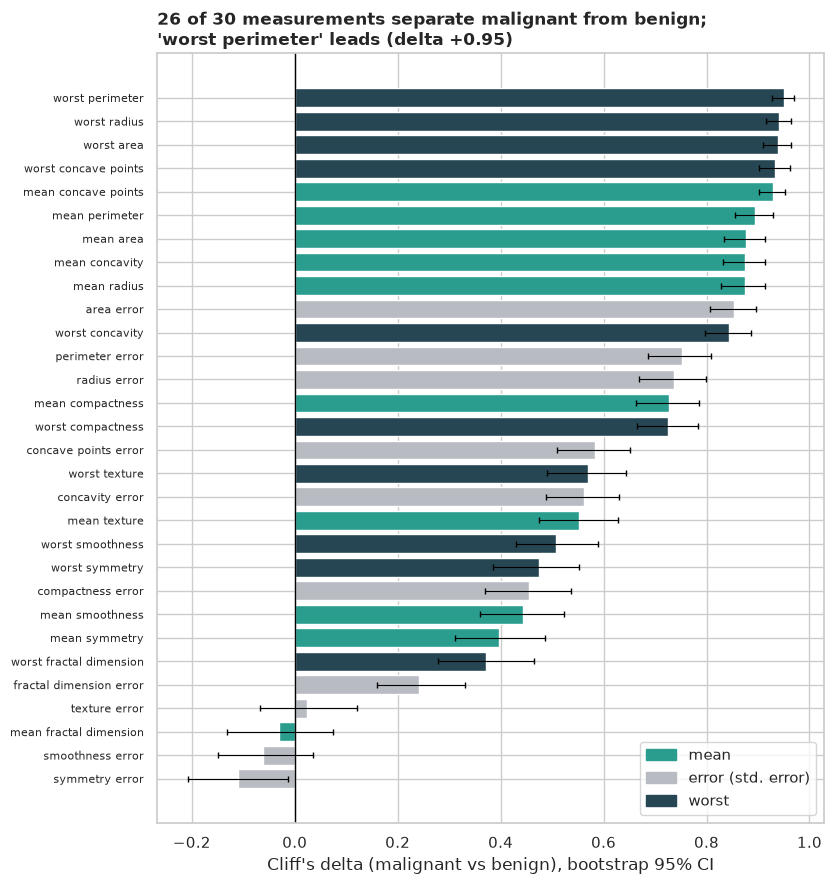

In [4]:
ordered = results.sort_values("delta")
fig, ax = plt.subplots(figsize=(8.5, 9))
ypos = np.arange(len(ordered))
ax.barh(ypos, ordered["delta"], color=[FAMILY_COLORS[f] for f in ordered["family"]])
ax.errorbar(ordered["delta"], ypos,
            xerr=[ordered["delta"] - ordered["ci_low"], ordered["ci_high"] - ordered["delta"]],
            fmt="none", ecolor="black", capsize=2, lw=0.8)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(ypos, ordered.index, fontsize=8)
ax.set_xlabel("Cliff's delta (malignant vs benign), bootstrap 95% CI")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
ax.legend(handles, ["mean", "error (std. error)", "worst"], loc="lower right")
top = results.iloc[0]
ax.set_title(f"{n_sig} of 30 measurements separate malignant from benign;\n"
             f"'{results.index[0]}' leads (delta {top['delta']:+.2f})", loc="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "01_effect_sizes.png", dpi=150)
plt.show()

**How to read this.** The dark "worst" bars and the teal "mean" bars (size and concavity measures) dominate the top. The grey "error" bars (how much the nuclei vary) are mostly weaker, with a few near zero at the bottom. Almost every whisker stays well on one side of 0, which matches the 26-of-30 count above.

### Seeing the separation

*What:* the distributions of the four strongest features for each class. *Why:* a δ near 0.95 is easier to believe once you see how little the two curves overlap.

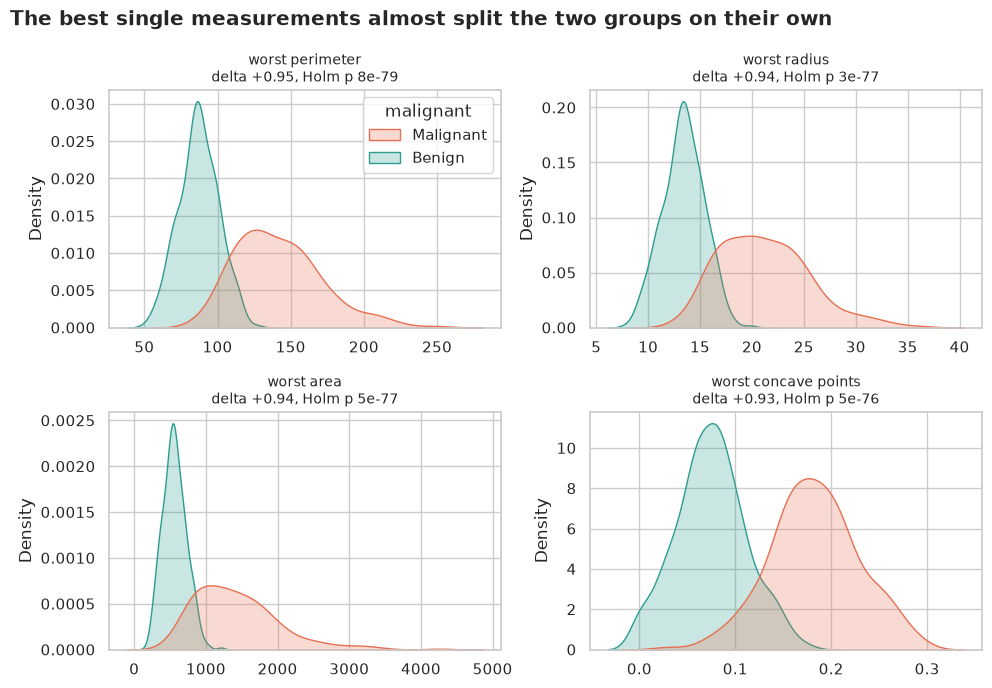

In [5]:
top_four = list(results.index[:4])
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
labels = y.map({1: "Malignant", 0: "Benign"})
for ax, feature in zip(axes.ravel(), top_four, strict=True):
    sns.kdeplot(x=X[feature], hue=labels, fill=True, common_norm=False,
                palette={"Malignant": ORANGE, "Benign": TEAL}, ax=ax, legend=ax is axes[0, 0])
    row = results.loc[feature]
    ax.set_title(f"{feature}\ndelta {row['delta']:+.2f}, Holm p {row['p_holm']:.0e}", fontsize=10)
    ax.set_xlabel("")
fig.suptitle("The best single measurements almost split the two groups on their own",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_top_feature_distributions.png", dpi=150)
plt.show()

**How to read this.** In each panel the orange curve (malignant) sits to the right of the teal curve (benign), with a small overlap in the middle. That overlap is where the mistakes will live: patients whose measurements look "in between".

## 6. H2: measurements that are copies of each other

Many of the 30 features are almost the same measurement taken three ways (or the same measurement in different units): a nucleus with a bigger **radius** has a bigger **perimeter** and **area** by pure geometry. Overlapping measurements cause two problems: they **inflate our sense of how much independent evidence we have**, and they make some models' coefficients **unstable and unreadable**.

### A correlation map, clustered

*What:* the correlation between every pair of features, with similar features moved next to each other (hierarchical clustering) so the "families" show up as blocks. *How to read:* dark red blocks are groups of near-copies; blue means they move in opposite directions.

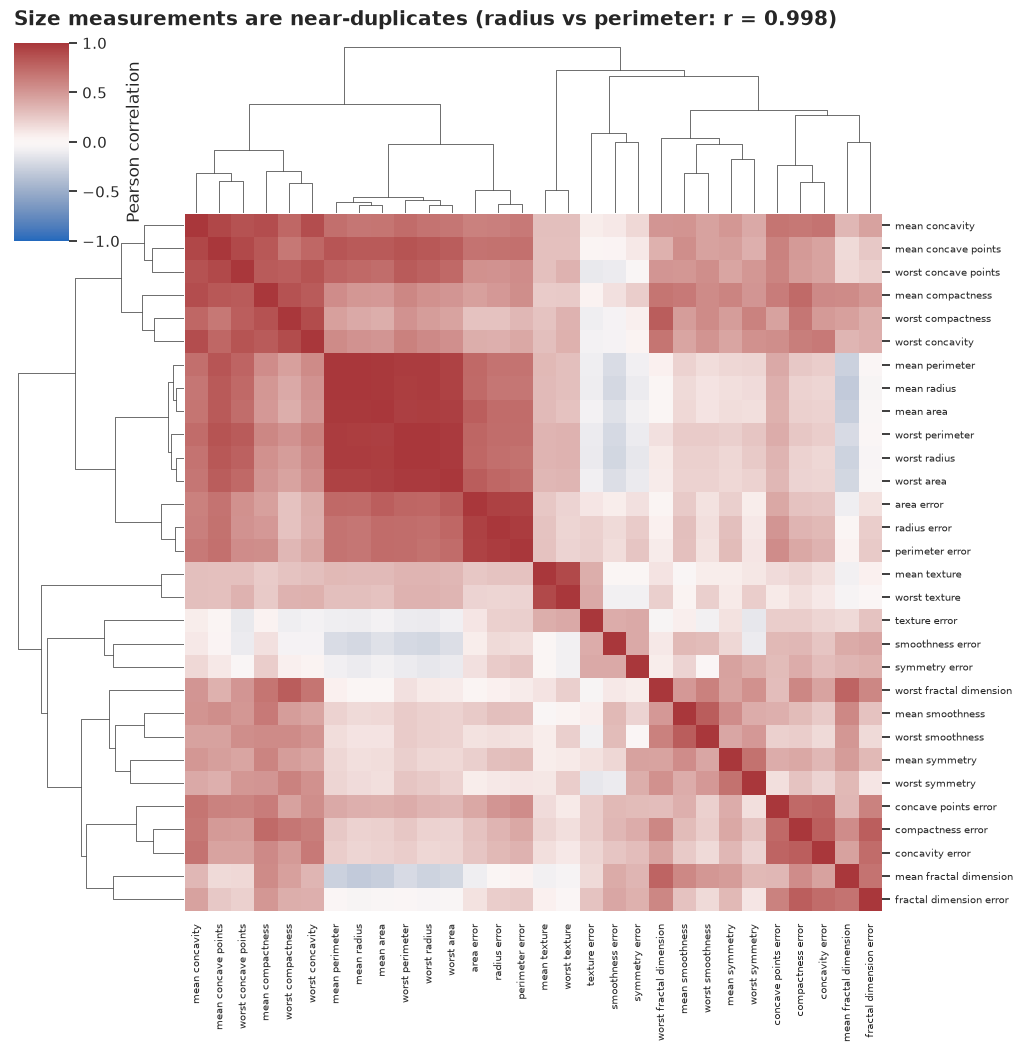

In [6]:
grid = sns.clustermap(X.corr(), cmap="vlag", center=0, vmin=-1, vmax=1, figsize=(11, 11),
                      linewidths=0, xticklabels=True, yticklabels=True,
                      cbar_kws={"label": "Pearson correlation"})
grid.ax_heatmap.tick_params(labelsize=7)
r_rp = X.corr().loc["mean radius", "mean perimeter"]
grid.figure.suptitle(
    f"Size measurements are near-duplicates (radius vs perimeter: r = {r_rp:.3f})",
    x=0.02, y=1.01, ha="left", fontweight="bold",
)
grid.savefig(OUT_DIR / "03_correlation_clusters.png", dpi=150)
plt.show()

**How to read this.** There is a big dark-red block of the size features (radius, perimeter, area, in their mean and worst versions), and a second block of the shape features (compactness, concavity, concave points). **`mean radius` and `mean perimeter` correlate at 0.998**: they're essentially the same number. The "error" features form their own looser group.

### How bad is the overlap? Variance inflation factors

*What:* the **VIF** says how much a coefficient's uncertainty is inflated by overlap with the other features. Rules of thumb: below 5 is fine, above 10 is a serious problem. We also use **PCA** (principal component analysis), which re-expresses the 30 features as a few *independent* "directions" and tells us how many we really need. The cumulative share of variance each one explains is the score.

In [7]:
design = sm.add_constant(X)
vif = pd.Series(
    {
        name: variance_inflation_factor(design.values, i)
        for i, name in enumerate(design.columns)
        if name != "const"
    },
    name="VIF",
).sort_values(ascending=False)
print(f"Features with VIF > 10: {(vif > 10).sum()} of 30   (VIF > 100: {(vif > 100).sum()})")
display(vif.head(6).round(0).to_frame().T)

scaled = StandardScaler().fit_transform(X)
pca = PCA().fit(scaled)
cumulative = np.cumsum(pca.explained_variance_ratio_)
n90, n95 = int(np.argmax(cumulative >= 0.90)) + 1, int(np.argmax(cumulative >= 0.95)) + 1
print(f"PC1 alone explains {pca.explained_variance_ratio_[0]:.1%} of the variance")
print(f"Components needed for 90% of the variance: {n90}; for 95%: {n95}")

Features with VIF > 10: 23 of 30   (VIF > 100: 6)


,mean radius,mean perimeter,worst radius,worst perimeter,mean area,worst area
VIF,3806.0,3786.0,799.0,405.0,348.0,337.0


PC1 alone explains 44.3% of the variance
Components needed for 90% of the variance: 7; for 95%: 10


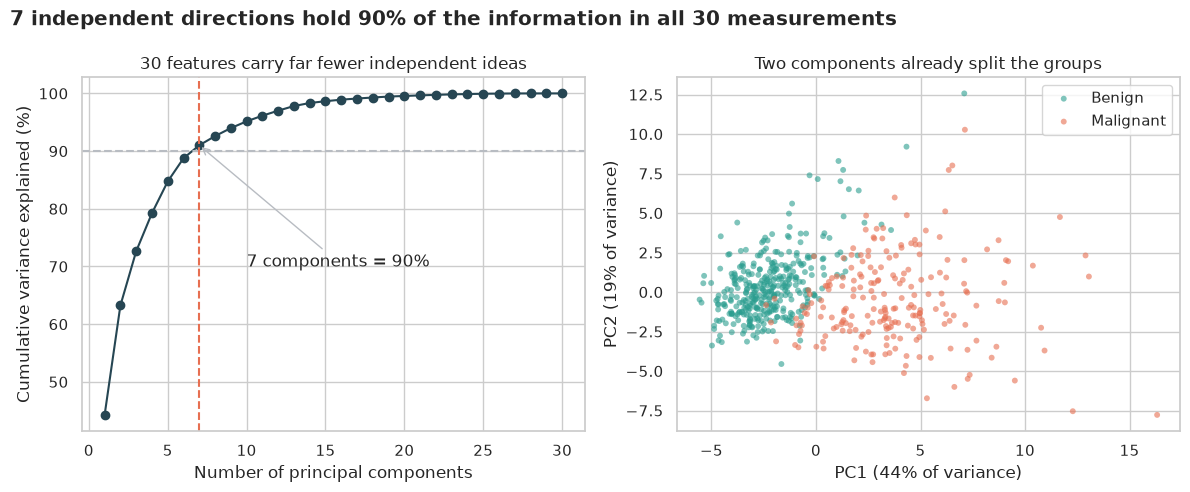

In [8]:
scores = pca.transform(scaled)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(range(1, 31), cumulative * 100, marker="o", color=NAVY)
axes[0].axhline(90, color=GREY, ls="--")
axes[0].axvline(n90, color=ORANGE, ls="--")
axes[0].annotate(f"{n90} components = 90%", (n90, cumulative[n90 - 1] * 100),
                 (n90 + 3, 70), arrowprops={"arrowstyle": "->", "color": GREY})
axes[0].set_xlabel("Number of principal components")
axes[0].set_ylabel("Cumulative variance explained (%)")
axes[0].set_title("30 features carry far fewer independent ideas")

for label, color, name in ((0, TEAL, "Benign"), (1, ORANGE, "Malignant")):
    axes[1].scatter(scores[y == label, 0], scores[y == label, 1], s=18, alpha=0.6, color=color,
                    label=name, edgecolor="none")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
axes[1].legend()
axes[1].set_title("Two components already split the groups")
fig.suptitle(f"{n90} independent directions hold 90% of the information in all 30 measurements",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "04_pca.png", dpi=150)
plt.show()

**How to read this.**

- **VIF:** **23 of the 30 features have a VIF above 10** and six are above 100. `mean radius` (VIF ≈ 3,800) and `mean perimeter` (≈ 3,800) are the extreme cases, the same number measured twice. Fitting an ordinary regression to all 30 would give wobbly, unreadable coefficients.
- **PCA:** the first component alone explains about **44%** of the variance (it is basically "overall tumour size and irregularity"), and **7 components capture 90%**, **10 capture 95%**. So the 30 columns hold roughly 7 to 10 independent ideas.
- **The scatter** shows that just the first two components already pull the orange (malignant) and teal (benign) groups into two mostly separate clouds.

This matters for how we model: we'll scale inside each pipeline, use **regularised** logistic regression (which tolerates overlapping features), and test whether the fancy models earn their complexity.

## 7. A short, readable model and its odds ratios

*What:* a doctor can't easily read 30 coefficients. We pick **one representative from each family that is not a near-copy of the others**: `worst radius` (size), `worst concave points` (dentedness), `worst texture` and `worst smoothness`. Their VIFs are all below 5, so they don't fight each other. We fit a **logistic regression** with `statsmodels`, which gives **odds ratios** with confidence intervals.

**Odds** are *chance of yes ÷ chance of no* (3 to 1 = 3). The **odds ratio (OR)** per 1 standard deviation says how much the odds of malignancy are *multiplied* when a feature goes up by one standard deviation, **holding the others fixed**. OR = 1 means no effect; OR = 2 means double. We z-score the features first so the ORs are comparable (this is for *explaining*, not predicting, so it isn't leakage).

In [9]:
short = ["worst radius", "worst concave points", "worst texture", "worst smoothness"]
Z = (X[short] - X[short].mean()) / X[short].std()
logit = sm.Logit(y, sm.add_constant(Z)).fit(disp=0)
or_ci = np.exp(logit.conf_int())
odds_table = pd.DataFrame({
    "odds_ratio_per_SD": np.exp(logit.params), "ci_low": or_ci[0], "ci_high": or_ci[1],
    "p": logit.pvalues,
}).drop(index="const")
short_vif = {
    name: variance_inflation_factor(sm.add_constant(X[short]).values, i + 1)
    for i, name in enumerate(short)
}
print("VIF of the four chosen features:", {k: round(v, 1) for k, v in short_vif.items()})
odds_table.style.format({"odds_ratio_per_SD": "{:.1f}", "ci_low": "{:.1f}", "ci_high": "{:.1f}",
                         "p": "{:.3f}"})

VIF of the four chosen features: {'worst radius': np.float64(3.3), 'worst concave points': np.float64(4.3), 'worst texture': np.float64(1.2), 'worst smoothness': np.float64(1.7)}


,odds_ratio_per_SD,ci_low,ci_high,p
worst radius,801.8,93.9,6846.1,0.000
worst concave points,9.0,2.1,37.9,0.003
worst texture,5.7,2.9,11.1,0.000
worst smoothness,3.1,1.3,7.1,0.008


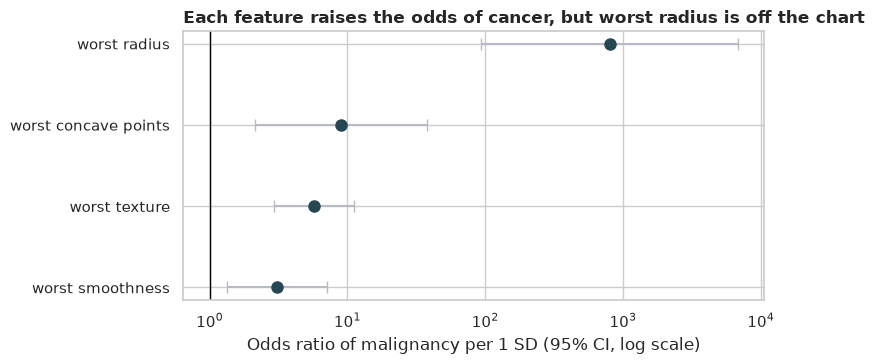

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ordered_or = odds_table.sort_values("odds_ratio_per_SD")
ypos = np.arange(len(ordered_or))
ax.errorbar(ordered_or["odds_ratio_per_SD"], ypos,
            xerr=[ordered_or["odds_ratio_per_SD"] - ordered_or["ci_low"],
                  ordered_or["ci_high"] - ordered_or["odds_ratio_per_SD"]],
            fmt="o", color=NAVY, ecolor=GREY, capsize=4, markersize=8)
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set_yticks(ypos, ordered_or.index)
ax.set_xlabel("Odds ratio of malignancy per 1 SD (95% CI, log scale)")
ax.set_title("Each feature raises the odds of cancer, but worst radius is off the chart",
             loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "05_odds_ratios.png", dpi=150)
plt.show()

**How to read this.** All four features raise the odds of malignancy, and all four intervals exclude 1. The numbers per 1 SD: `worst texture` ×5.7 (CI about 2.9 to 11), `worst smoothness` ×3.1 (1.3 to 7.1), `worst concave points` ×9.0 (2.1 to 38).

**The warning sign:** `worst radius` has an odds ratio of about **800** with a CI from about 94 to about 6,800. Believe the *direction* but not the *size*. When one feature nearly separates the classes, logistic regression is pushed towards "infinite" coefficients (this is called **near-perfect separation**) and the estimate becomes huge and imprecise. The enormous, lopsided CI is the model telling us exactly that. It is also why, for **prediction**, we'll use a *regularised* logistic regression, which keeps coefficients in check.

## 8. H3: a leak-free model ladder

*What:* the tests show the measurements carry signal. Now the practical question: **how well, and how safely, can a model use them to classify new patients?** We build a ladder from lazy to fancy:

1. **Majority class**, which always says "benign". The bar to beat.
2. **Logistic regression** with the penalty strength chosen by cross-validation (`LogisticRegressionCV`).
3. **SVM** (RBF kernel) with its settings tuned by an inner grid search.
4. **k-nearest neighbours** (k = 15), **Gaussian naive Bayes**, a **shallow decision tree** (depth 3).
5. **Random forest** and **gradient boosting** (`HistGradientBoostingClassifier`).

**How we avoid cheating (data leakage).** If you scale or tune using *all* the patients and then split, the test patients have secretly shaped the model, like a student who saw the exam while making study notes. We put the scaling **and the tuning** inside each model's `Pipeline`, so they're redone on the training patients only, in every fold. The tuned models (logistic regression and SVM) use an *inner* cross-validation loop inside each *outer* training set. This is called **nested cross-validation**, and it keeps the reported scores honest.

**How we score.**

- **ROC-AUC:** the chance the model scores a random malignant patient higher than a random benign one (0.5 = coin flip, 1.0 = perfect).
- **Sensitivity** (malignant caught), **specificity** (benign correctly cleared), **accuracy**.
- We use **5-fold stratified cross-validation repeated 10 times** (50 train/test splits) and the **Nadeau-Bengio correction** for confidence intervals: the 50 scores aren't independent, because the splits reuse mostly the same patients, much like judges who all read the same pages of a report, so a plain interval would be too narrow.

In [11]:
def build_models() -> dict[str, Pipeline]:
    """Builds the model ladder. Scaling and tuning live inside each pipeline (no leakage).

    Returns:
        Model name mapped to an unfitted pipeline.
    """
    inner_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    return {
        "Majority class": make_pipeline(DummyClassifier(strategy="prior")),
        "Logistic regression (tuned)": make_pipeline(
            StandardScaler(),
            LogisticRegressionCV(Cs=np.logspace(-3, 2, 12), cv=inner_cv, scoring="roc_auc",
                                 l1_ratios=(0.0,), use_legacy_attributes=False, max_iter=5000),
        ),
        "SVM, RBF (tuned)": make_pipeline(
            StandardScaler(),
            GridSearchCV(SVC(), {"C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.003]},
                         cv=inner_cv, scoring="roc_auc"),
        ),
        "k-nearest neighbours (k=15)": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
        "Gaussian naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
        "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
        "Random forest": RandomForestClassifier(300, random_state=SEED, n_jobs=-1),
        "Gradient boosting": HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED
        ),
    }


def corrected_ci(scores: np.ndarray, n_train: int, n_test: int) -> tuple[float, float, float]:
    """95% CI for a mean CV score using the Nadeau-Bengio variance correction.

    Args:
        scores: Per-split scores.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        Mean, CI lower bound, CI upper bound (upper bound capped at 1).
    """
    k = len(scores)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(scores, ddof=1))
    half = stats.t.ppf(0.975, k - 1) * se
    return float(scores.mean()), float(scores.mean() - half), float(min(1.0, scores.mean() + half))


def corrected_paired_p(diff: np.ndarray, n_train: int, n_test: int) -> float:
    """Two-sided p-value for "do two models differ?" on identical splits.

    Args:
        diff: Per-split score differences between two models.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        p-value from the corrected resampled t-test.
    """
    k = len(diff)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(diff, ddof=1))
    return float(2 * stats.t.sf(abs(diff.mean() / se), k - 1))

Now run the cross-validation. Every model sees **exactly the same 50 splits**, which is what allows the *paired* comparison afterwards. (This cell takes about a minute.)

In [12]:
cv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
n_test = len(X) // CV_SPLITS
n_train = len(X) - n_test
scoring = {
    "auc": "roc_auc",
    "accuracy": "accuracy",
    "sensitivity": "recall",
    "specificity": make_scorer(recall_score, pos_label=0),
}

fold_scores, rows = {}, {}
for name, model in build_models().items():
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    fold_scores[name] = {m: res[f"test_{m}"] for m in scoring}
    row = {}
    for metric, values in fold_scores[name].items():
        mean, lo, hi = corrected_ci(values, n_train, n_test)
        row[metric], row[f"{metric}_low"], row[f"{metric}_high"] = mean, lo, hi
    rows[name] = row

summary = pd.DataFrame(rows).T
summary[["auc", "accuracy", "sensitivity", "specificity"]].round(3)

,auc,accuracy,sensitivity,specificity
Majority class,0.500,0.627,0.000,1.000
Logistic regression (tuned),0.994,0.975,0.943,0.994
"SVM, RBF (tuned)",0.995,0.975,0.953,0.987
k-nearest neighbours (k=15),0.991,0.959,0.901,0.993
Gaussian naive Bayes,0.986,0.932,0.896,0.954
Decision tree (depth 3),0.938,0.928,0.883,0.954
Random forest,0.990,0.959,0.933,0.974
Gradient boosting,0.992,0.967,0.939,0.983


**How to read this.** (All scores are on patients the model never saw during training.)

- **Majority class:** accuracy **62.7%** with sensitivity **0**: it never catches a single cancer. The bar to beat.
- **Tuned logistic regression and the tuned SVM lead**: ROC-AUC ≈ **0.994 to 0.995** and accuracy ≈ **97.5%**, with specificity of 98.7% to 99.4%.
- **Sensitivity is the weak spot:** even the best models catch only about **94% to 95%** of malignant tumours at the default decision threshold of 0.5, so roughly 1 in 18 cancers is missed. Hold on to that number; section 9 is about fixing it.
- **The shallow decision tree is clearly the weakest** (AUC ≈ 0.94, sensitivity ≈ 88%). It is readable but throws away too much.
- **Random forest and gradient boosting do not beat the simple models**: AUC ≈ 0.990 and 0.992.

Are those differences real, or just noise between splits? The paired test settles it.

In [13]:
reference = "Logistic regression (tuned)"
comparison = {}
for name, scores in fold_scores.items():
    if name in (reference, "Majority class"):
        continue
    diff = scores["auc"] - fold_scores[reference]["auc"]
    comparison[name] = {
        "AUC minus logistic": diff.mean(),
        "paired p": corrected_paired_p(diff, n_train, n_test),
    }
pd.DataFrame(comparison).T.style.format({"AUC minus logistic": "{:+.4f}", "paired p": "{:.3f}"})

,AUC minus logistic,paired p
"SVM, RBF (tuned)",+0.0009,0.683
k-nearest neighbours (k=15),-0.0033,0.358
Gaussian naive Bayes,-0.0079,0.107
Decision tree (depth 3),-0.0562,0.000
Random forest,-0.0044,0.305
Gradient boosting,-0.0019,0.465


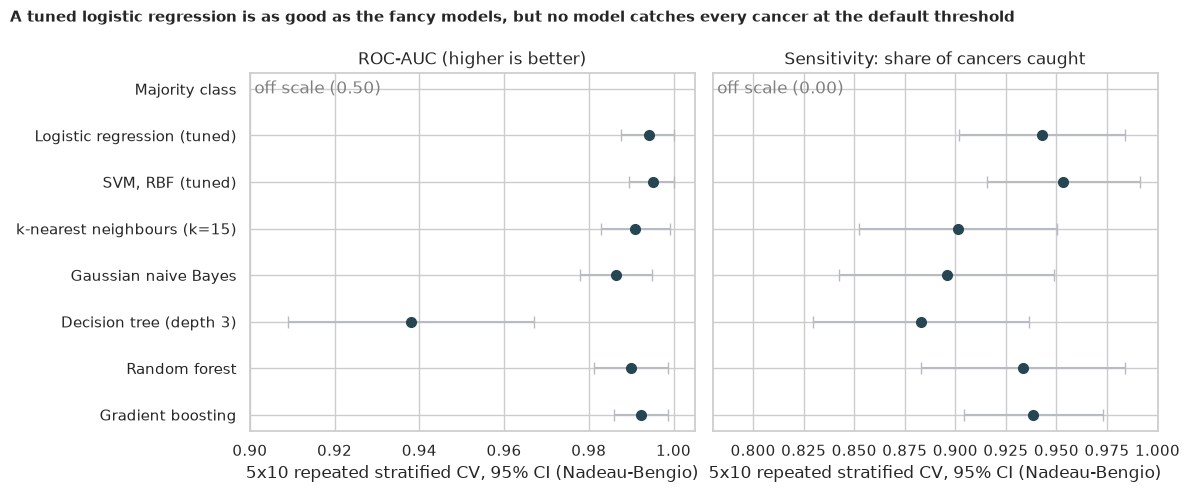

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
names = list(summary.index)
ypos = np.arange(len(names))
for ax, metric, title, xlim in (
    (axes[0], "auc", "ROC-AUC (higher is better)", (0.9, 1.005)),
    (axes[1], "sensitivity", "Sensitivity: share of cancers caught", (0.78, 1.0)),
):
    ax.errorbar(summary[metric], ypos,
                xerr=[summary[metric] - summary[f"{metric}_low"],
                      summary[f"{metric}_high"] - summary[metric]],
                fmt="o", color=NAVY, ecolor=GREY, capsize=4, markersize=7)
    ax.set_xlim(*xlim)
    ax.text(xlim[0] + 0.01 * (xlim[1] - xlim[0]), 0, f"off scale ({summary[metric].iloc[0]:.2f})",
            va="center", color="grey")
    ax.set_title(title)
    ax.set_xlabel("5x10 repeated stratified CV, 95% CI (Nadeau-Bengio)")
axes[0].set_yticks(ypos, names)
axes[0].invert_yaxis()
fig.suptitle("A tuned logistic regression is as good as the fancy models, but no model "
             "catches every cancer at the default threshold",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "06_model_comparison.png", dpi=150)
plt.show()

**How to read this (paired test table and chart).**

- The paired test compares each model's per-split AUC with the logistic regression's. **None of the non-trivial models is distinguishable from logistic regression** (all p-values above 0.05), except possibly the decision tree, which is clearly *worse*. So **H₀ stands: the transparent linear model is as good as the complicated ones.**
- On the right-hand chart the whiskers are wide for sensitivity because only 212 malignant patients (about 42 per test fold) are available to measure it. The chart shows **no model reliably reaches 99% sensitivity at the default threshold**. Better *algorithms* won't fix that; a different *threshold* might.

## 9. H4: the safety trade-off

*What:* a classifier doesn't just say "malignant / benign"; it first produces a **probability** and then applies a **threshold** (default 0.5: "above 50% means malignant"). Lowering the threshold makes the alarm more sensitive: it catches more cancers, but flags more benign lumps for a second look. Since missing a cancer is the worse mistake, we ask: **how low must the threshold go to catch at least 99% of cancers, and what does it cost in false alarms?**

*How:* we use `cross_val_predict` to get a probability for **every patient from a model that never saw that patient**, then draw the **ROC curve** (sensitivity against false-alarm rate across *all* thresholds) and read off two operating points.

> *A fairness note:* we choose the 99% threshold using these same out-of-fold probabilities, which makes the reported specificity slightly optimistic. A truly independent test would need new patients.

In [15]:
model = build_models()["Logistic regression (tuned)"]
proba = cross_val_predict(
    model, X, y, cv=StratifiedKFold(10, shuffle=True, random_state=SEED), method="predict_proba"
)[:, 1]
fpr, tpr, thresholds = roc_curve(y, proba)
oof_auc = roc_auc_score(y, proba)
safe_idx = int(np.argmax(tpr >= TARGET_SENSITIVITY))
safe_threshold = float(thresholds[safe_idx])


def confusion_at(threshold: float) -> pd.DataFrame:
    """Confusion counts for a decision threshold on the out-of-fold probabilities.

    Args:
        threshold: Probability at or above which we call a tumour malignant.

    Returns:
        2x2 table with truth on rows and the alarm's call on columns.
    """
    called = pd.Series(proba >= threshold, index=y.index).map({True: "alarm", False: "no alarm"})
    truth = y.map({1: "malignant", 0: "benign"})
    table = pd.crosstab(truth, called, rownames=["truth"], colnames=["alarm's call"])
    return table.reindex(columns=["no alarm", "alarm"])


summary_rows = {}
for label, threshold in (("default 0.50", 0.5), (f"safe {safe_threshold:.2f}", safe_threshold)):
    table = confusion_at(threshold)
    tp, fn = table.loc["malignant", "alarm"], table.loc["malignant", "no alarm"]
    fp, tn = table.loc["benign", "alarm"], table.loc["benign", "no alarm"]
    summary_rows[label] = {
        "missed cancers": fn, "false alarms": fp, "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp), "precision": tp / (tp + fp),
    }
trade_off = pd.DataFrame(summary_rows).T
print(f"Out-of-fold ROC-AUC: {oof_auc:.3f}")
print(f"Threshold giving at least {TARGET_SENSITIVITY:.0%} sensitivity: {safe_threshold:.3f}")
display(confusion_at(0.5))
display(confusion_at(safe_threshold))
trade_off.style.format({"missed cancers": "{:.0f}", "false alarms": "{:.0f}",
                        "sensitivity": "{:.1%}", "specificity": "{:.1%}", "precision": "{:.1%}"})

Out-of-fold ROC-AUC: 0.994
Threshold giving at least 99% sensitivity: 0.107


alarm's call,no alarm,alarm
truth,,
benign,353,4
malignant,9,203


alarm's call,no alarm,alarm
truth,,
benign,309,48
malignant,2,210


,missed cancers,false alarms,sensitivity,specificity,precision
default 0.50,9,4,95.8%,98.9%,98.1%
safe 0.11,2,48,99.1%,86.6%,81.4%


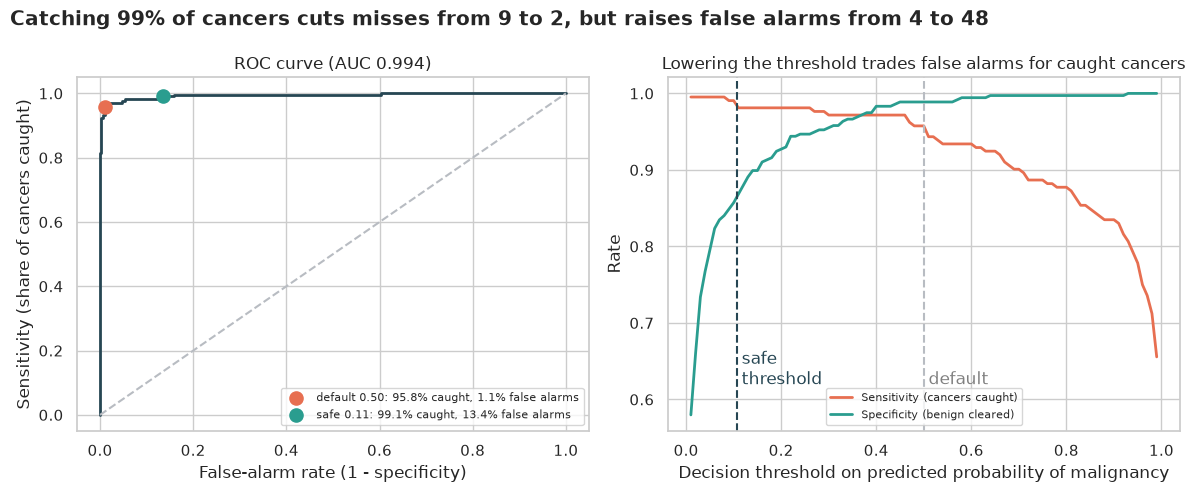

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, color=NAVY, lw=2)
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--")
default_sens = (proba[y == 1] >= 0.5).mean()
default_fpr = (proba[y == 0] >= 0.5).mean()
axes[0].scatter(default_fpr, default_sens, s=90, color=ORANGE, zorder=3,
                label=f"default 0.50: {default_sens:.1%} caught, {default_fpr:.1%} false alarms")
axes[0].scatter(fpr[safe_idx], tpr[safe_idx], s=90, color=TEAL, zorder=3,
                label=f"safe {safe_threshold:.2f}: {tpr[safe_idx]:.1%} caught, "
                      f"{fpr[safe_idx]:.1%} false alarms")
axes[0].set_xlabel("False-alarm rate (1 - specificity)")
axes[0].set_ylabel("Sensitivity (share of cancers caught)")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].set_title(f"ROC curve (AUC {oof_auc:.3f})")

grid_t = np.linspace(0.01, 0.99, 99)
sens = [(proba[y == 1] >= t).mean() for t in grid_t]
spec = [(proba[y == 0] < t).mean() for t in grid_t]
axes[1].plot(grid_t, sens, color=ORANGE, lw=2, label="Sensitivity (cancers caught)")
axes[1].plot(grid_t, spec, color=TEAL, lw=2, label="Specificity (benign cleared)")
axes[1].axvline(safe_threshold, color=NAVY, ls="--")
axes[1].axvline(0.5, color=GREY, ls="--")
axes[1].text(safe_threshold + 0.01, 0.62, "safe\nthreshold", color=NAVY)
axes[1].text(0.51, 0.62, "default", color="grey")
axes[1].set_xlabel("Decision threshold on predicted probability of malignancy")
axes[1].set_ylabel("Rate")
axes[1].legend(loc="lower center", fontsize=8)
axes[1].set_title("Lowering the threshold trades false alarms for caught cancers")

fn_default, fn_safe = (int(trade_off.iloc[i]["missed cancers"]) for i in (0, 1))
fp_default, fp_safe = (int(trade_off.iloc[i]["false alarms"]) for i in (0, 1))
fig.suptitle(f"Catching 99% of cancers cuts misses from {fn_default} to {fn_safe}, but raises "
             f"false alarms from {fp_default} to {fp_safe}", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "07_threshold_tradeoff.png", dpi=150)
plt.show()

**How to read this.**

- **At the default threshold (0.50):** of 212 malignant tumours, **9 are missed** (sensitivity 95.8%), and of 357 benign ones only **4 trigger a false alarm** (specificity 98.9%). Precision (when the alarm rings, how often is it a real cancer?) is 98.1%.
- **At the "safe" threshold (about 0.11):** sensitivity reaches **99.1%**, so only **2 cancers are missed**. The price: **48 false alarms** instead of 4, specificity falls to about 86.6% and precision to about 81%.
- **The trade-off in plain terms:** to rescue the 7 extra cancers (9 → 2) we accept about 44 extra benign patients being called back for a second look: roughly **6 extra false alarms per cancer rescued**. Whether that's acceptable is a *clinical and ethical* decision (a callback is an extra test and some anxiety; a missed cancer can be fatal), not a statistical one. What the statistics can do is lay the trade-off out honestly.
- Right-hand chart: the orange (sensitivity) curve climbs as the threshold drops, while the teal (specificity) curve falls, and the two lines mark the default and safe thresholds. The model's **ranking** is excellent (out-of-fold AUC ≈ 0.994); what moves along the curve is only where we choose to draw the line.

## 10. 🎯 Takeaways

1. **26 of 30 measurements differ significantly between malignant and benign** (Mann-Whitney, Holm-corrected). The "worst" size and shape measures are strongest: `worst perimeter` has Cliff's δ ≈ +0.95, i.e. an AUC of about 0.975 on its own.
2. **The 30 features are about 7 to 10 independent ideas.** `mean radius` and `mean perimeter` correlate at 0.998, and 23 features have VIF above 10, so individual coefficients from an unregularised model can't be trusted.
3. **A tuned logistic regression is as good as the fancy models** (AUC ≈ 0.994, accuracy ≈ 97.5%; no paired test separates it from SVM, forests or boosting). Complexity bought nothing.
4. **Accuracy hides what matters.** At the default threshold roughly 1 in 18 cancers is missed. Moving the threshold to reach 99% sensitivity cuts misses from 9 to 2, at the cost of roughly 6 extra false alarms per cancer rescued.
5. **Odds ratios can mislead when a feature nearly separates the classes.** `worst radius` gives OR ≈ 800 with a CI from 94 to 6,800: trust the direction, not the number.

## 11. ⚠️ Limitations and edge cases

- **Association, not diagnosis.** These are measurements of cell nuclei taken from lumps that were *already examined*; the model is a decision aid for that setting, not a general screening test.
- **Small, single-source data.** 569 patients from one study (Wisconsin, 1990s), with no information on demographics or imaging equipment. Performance on other hospitals' images is unknown.
- **Few malignant cases.** With 212 malignant tumours, sensitivity estimates have wide intervals (about ±4 points).
- **Threshold chosen on the same out-of-fold data.** The 99%-sensitivity operating point and its specificity are slightly optimistic. A real deployment would fix the threshold on one data set and confirm it on another.
- **Correlated features.** Tests on 30 overlapping features overstate how many independent facts we have; "26 of 30 significant" is really "several families of measurement are significant".
- **Tuning scope.** The tuned models search a small grid, and trees, forests and boosting use sensible defaults rather than a full search, so a heavily tuned ensemble might do slightly better. We found no evidence that it would do so meaningfully.
- **Label noise.** The "ground truth" labels come from clinical diagnosis, which is itself not perfect.

---
*Run `uv run jupyter nbconvert --to html --execute ML/breast-cancer-wisconsin/01_breast_cancer.ipynb --output-dir docs --output ml-breast-cancer-wisconsin` to rebuild the web version (`docs/ml-breast-cancer-wisconsin.html`).*